# Reverse-engineering how an agent chooses: the full pipeline

**The question.** An agent (here GPT, or a simulated policy) is shown *K* candidate patches cut from an AFM scan and picks one, step after step. We only see which patch it picked. What rule produced those picks?

**The approach.** Describe every patch with a *representation* (e.g. 34 interpretable descriptors), assume the agent gives each patch a *reward* that depends on that description, and that it picks with probability

$$P(\text{pick } i) = \frac{e^{f(x_i)}}{\sum_j e^{f(x_j)}}$$

(a softmax, or conditional-logit, choice model). Different *reward models* make different assumptions about *f*: one property, a sparse or dense weighted sum, or any smooth function (a Gaussian process). Everything is fitted with this one likelihood and scored with one protocol, so the methods can be compared directly.

**What this notebook does**, step by step, and which figure each step makes:

| Step | Question | Output | Slide |
|---|---|---|---|
| 1 | What are the data? Which agents saw identical candidates? | Figure 1 | 1 |
| 2 | How is a patch described? | descriptor table | 3 |
| 3 | **Test 1.** Does any weighted sum of the descriptors reproduce *every* pick? | Figure 2 | 4 |
| 4 | **Test 2.** Which method predicts picks it never saw? | Figure 3 | 5 |
| 5 | **Ground truth.** Can the methods recover rules we wrote ourselves? | Figure 4, recovery chart | 2 |
| 6 | **How do the target agents decide?** Content vs chance, which properties, memory, similarity to known rules, consistency between runs | Figure 6 | 6–9 |
| 7 | Where on the scan does each learned rule point? Which kinds of structure does it prefer? | Figure 5 | 10 |
| 8 | Key numbers | printed summary + saved results | 11–12 |

## How to adapt it

Everything that defines the study is in the **Configuration** cells (section 0). Change them and rerun all cells; nothing below them needs editing.

| To… | Change |
|---|---|
| use another scan or other traces | `load_data()` |
| say which agents to explain and which are known references | `TARGETS`, `CONTROLS` |
| add, remove or replace descriptors | `DESC` (`.add`, `.drop`, `.select`, or a new `ck.DescriptorSet`) |
| add a different description of patches (e.g. embeddings from an image model) | `REPRESENTATIONS` (`ck.Precomputed(array, name)`) |
| compare other reward models | `METHODS` |
| test other known rules, noise levels or amounts of data | `SYNTH_REWARDS`, `SYNTH_GRID`, `SYNTH_MODELS` |
| change test settings, maps or figure panels | `DIAG`, `MAP_MODEL`, `MAP_PANELS` |
| try a new configuration quickly | `FAST = True` |

**Long computations are cached.** The benchmark (step 4) and the synthetic experiments (step 5) take hours. Every long result is saved in `results/cache/` under a fingerprint of everything that determines it (the data, the descriptors, the model settings, the reward functions). Rerunning with the same configuration loads it in seconds; changing anything that matters recomputes it. The results of the study configuration are shipped, so this notebook runs as-is in a few minutes. Set `RECOMPUTE = True` to recompute everything.

The code that does the work is in the `choicekit` package next to this notebook (`representations.py`, `models.py`, `evaluate.py`, `diagnostics.py`, `synthetic.py`, `plots.py`).

### Where to run it
**Locally:** unzip `choicekit_day20.zip` and open this notebook from its `examples/` folder.

**Google Colab (or anywhere with internet):** open only this notebook and run the cell below. It downloads `choicekit_day20.zip` (the package, the data and the saved results) from Google Drive with `gdown`, unpacks it and moves into its `examples/` folder. If the download fails, it asks you to upload the zip instead. A copy of the zip in your own Drive can be used by setting `BUNDLE` to its path, e.g. `/content/drive/MyDrive/choicekit_day20.zip` (the cell mounts Drive). Colab already has every library needed (numpy, scipy, pandas, scikit-learn, matplotlib); `igor2` is needed only to read the original `.ibw` scan.

In [ ]:
import os, sys, glob, zipfile
BUNDLE = None                                    # e.g. "/content/drive/MyDrive/choicekit_day20.zip"
BUNDLE_URL = "https://drive.google.com/uc?id=1GRhehp7sHvi95ZvlIi0HGBQj9WUefdaF"

if not os.path.isdir("../choicekit"):
    if os.path.isdir("choicekit_day20/examples"):
        os.chdir("choicekit_day20/examples")
    else:
        if BUNDLE and BUNDLE.startswith("/content/drive") and not os.path.isdir("/content/drive"):
            from google.colab import drive; drive.mount("/content/drive")
        zips = [BUNDLE] if BUNDLE else sorted(glob.glob("choicekit_day20*.zip"))
        if not zips:
            try:
                import gdown
            except ImportError:
                import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
                import gdown
            try:
                out = gdown.download(BUNDLE_URL, "choicekit_day20.zip", quiet=False)
                if out and zipfile.is_zipfile(out): zips = [out]
            except Exception as e:
                print("download failed:", e)
        if not zips and "google.colab" in sys.modules:
            from google.colab import files
            print("Upload choicekit_day20.zip"); zips = list(files.upload())
        if not zips:
            raise FileNotFoundError("Open this notebook from the examples/ folder of the bundle, "
                                    "or put choicekit_day20.zip next to it.")
        zipfile.ZipFile(zips[0]).extractall(".")
        os.chdir("choicekit_day20/examples")
print("working folder:", os.getcwd())

Downloading...
From (original): https://drive.google.com/uc?id=1GRhehp7sHvi95ZvlIi0HGBQj9WUefdaF
From (redirected): https://drive.google.com/uc?id=1GRhehp7sHvi95ZvlIi0HGBQj9WUefdaF&confirm=t&uuid=282a27e8-ab39-4c04-b5ef-3a7c46eb4692
To: /content/choicekit_day20.zip
100%|██████████| 48.6M/48.6M [00:00<00:00, 145MB/s]


working folder: /content/choicekit_day20/examples


In [ ]:
import os, sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

sys.path.insert(0, "..")                       # folder that contains the choicekit package
import choicekit as ck
from choicekit import diagnostics as dg, synthetic as sy, plots
from choicekit._lp import max_margin
plots.setup()

## 0. Configuration

### 0.1 Data and agents
`load_data()` must return a `ck.ChoiceData`: the scan, every candidate as an index into the library of all *p*×*p* crops of the scan, and the picks. Three loaders are provided:

* `ck.load_arrays(path)`: the arrays shipped in `data/` (no other files needed);
* `ck.hackathon_day20(folder)`: the original `.ibw` scan and `.pkl` traces;
* `ck.from_pickles(scan, [trace files], labels)` or `ck.from_arrays(image, cand, choice, labels)` for new data.

**Targets** are the agents we want to explain. **Controls** are agents with fixed, memoryless rules; they serve as reference strategies and as negative controls (e.g. for the memory test).

In [ ]:
def load_data():
    return ck.load_arrays("../data/day20_arrays.npz")
    # return ck.hackathon_day20("day_20_data")          # from the original files

TARGETS = ["GPT-0", "GPT-1", "GPT-2"]
CONTROLS = [f"Sim-{i}" for i in range(8)]

# short descriptions used in figure labels (optional)
AGENT_NOTES = {"Sim-0": "brightest", "Sim-1": "darkest", "Sim-2": "flattest", "Sim-3": "unknown",
               "Sim-4": "vertical stripes", "Sim-5": "horizontal stripes", "Sim-6": "fine texture", "Sim-7": "two-tone"}

### 0.2 How a patch is described
`DESC` is the set of interpretable descriptors. Each descriptor has a name, a family and a meaning, and is computed by a function of the crops. Families drive the family-importance test (step 6) and the figure labels. Examples of changes:

```python
DESC = DESC.add("dark_fraction", "intensity", "fraction of pixels below 0.3",
                lambda P: (P < 0.3).mean((1, 2)))            # P: crops, shape (n, p, p), values in [0, 1]
DESC = DESC.drop(["tb_step", "lr_step"])                      # remove some
DESC = ck.DescriptorSet.builtin(["mean", "std", "coherence"]) # start from a subset
```

`REPRESENTATIONS` lists every description used anywhere. `PRIMARY` is the interpretable one used for Test 1, the diagnostics and the reward maps. A representation from elsewhere (e.g. embeddings from a pretrained image model, one row per crop) is added with `ck.Precomputed(array, name)`.

In [ ]:
DESC = ck.DescriptorSet.builtin()                 # the 34 descriptors of the study

REPRESENTATIONS = {
    "descriptors": DESC,
    "pixel PCA": ck.PixelPCA(20),                   # 20 whitened principal components of raw pixels
    "structure classes": ck.StructureClasses(),     # fraction of flat / striped / boundary / irregular area
}
PRIMARY = "descriptors"

### 0.3 Methods compared in Test 2
Each method is a (representation, reward model) pair. Reward models: `ck.SingleFeature()` (one property, with sign), `ck.LinearLogit("l1")` (sparse weighted sum), `ck.LinearLogit("l2")` (dense weighted sum), `ck.GPPreference()` (any smooth function). Penalties and GP settings are chosen inside each training fold. Any object with `fit(E, cand, y)` and `reward(E, idx)` works.

In [ ]:
METHODS = {
    "best single descriptor":          ("descriptors", ck.SingleFeature()),
    "sparse linear, descriptors":      ("descriptors", ck.LinearLogit("l1")),
    "dense linear, descriptors":       ("descriptors", ck.LinearLogit("l2")),
    "GP, descriptors":                 ("descriptors", ck.GPPreference()),
    "dense linear, pixel PCA":         ("pixel PCA", ck.LinearLogit("l2")),
    "GP, pixel PCA":                   ("pixel PCA", ck.GPPreference()),
    "dense linear, structure classes": ("structure classes", ck.LinearLogit("l2")),
}
CV = dict(folds=5, repeats=2, seed=100)             # same folds for every method

### 0.4 Synthetic agents with known rules
Each entry is a true reward per crop, written as a function of `d` (the primary descriptors, standardised, as a table with one column per descriptor) and `emb` (all representations). The agent picks the highest-reward candidate after adding softmax noise of temperature τ (τ = 0: always the best). Each method then sees only the picks and we measure how well it recovers the true reward (Spearman correlation over crops).

`SYNTH_MODELS` entries are (representation, reward model[, largest number of decisions to run it on]).

In [ ]:
def template_crop(n_crops, seed=0):
    """Index of the crop used as the texture template in the study."""
    rng = np.random.default_rng(seed); rng.choice(n_crops, 6000, replace=False)
    return int(rng.integers(n_crops))

SYNTH_REWARDS = {
    "single (brightness)":             lambda d, emb: d["mean"],
    "sparse mix (3 features)":         lambda d, emb: 0.2 * d["mean"] - 0.5 * d["std"] + 0.6 * d["coherence"],
    "nonlinear (moderate contrast)":   lambda d, emb: -(d["std"] - 0.5) ** 2,
    "outside library (texture match)": lambda d, emb: -np.linalg.norm(emb["pixel PCA"][:, :10] - emb["pixel PCA"][template_crop(len(d)), :10], axis=1),
}
SYNTH_MODELS = {
    "single":  ("descriptors", ck.SingleFeature()),
    "l1_desc": ("descriptors", ck.LinearLogit("l1", grid=[1.0])),
    "l2_desc": ("descriptors", ck.LinearLogit("l2", grid=[1.0])),
    "gp_desc": ("descriptors", ck.GPPreference(), 100),
    "gp_pix":  ("pixel PCA", ck.GPPreference(), 100),
}
SYNTH_LABELS = {"single": "best single descriptor", "l1_desc": "sparse linear (descriptors)",
                "l2_desc": "dense linear (descriptors)", "gp_desc": "GP (descriptors)", "gp_pix": "GP (pixel PCA)"}
SYNTH_GRID = dict(temperatures=[0.0, 0.5, 1.0], n_decisions=[25, 50, 100, 200, 400], replicates=3)
SYNTH_TITLES = {"single (brightness)": "single feature\n(brightness)", "sparse mix (3 features)": "linear mix\n(3 features)",
                "nonlinear (moderate contrast)": "nonlinear\n(moderate contrast)",
                "outside library (texture match)": "outside the library\n(texture template)"}
# lines on the slide chart: (true reward, model, label, colour slot, line style, marker)
RECOVERY_CHART = [("sparse mix (3 features)", "l1_desc", "linear rule, linear model", 0, "-", "o"),
                  ("nonlinear (moderate contrast)", "gp_desc", "nonlinear rule, GP", 1, "-", "s"),
                  ("nonlinear (moderate contrast)", "l1_desc", "nonlinear rule, linear model", 1, ":", "s")]

### 0.5 Diagnostics, reward maps and run control

In [ ]:
DIAG = dict(n_perm=100,                 # random-pick copies in the permutation test
            stability_l1=4.0, stability_n=200,   # sparse refits on random halves (stability selection)
            rule_l2=0.1,                 # penalty for the control agents' linear rules (similarity test)
            consistency_l2=10.0)

# model used to draw each agent's reward map (default for agents not listed: sparse linear)
MAP_MODEL = {"GPT-0": "GP", "GPT-1": "GP", "Sim-3": "GP", "Sim-6": "GP"}
MAP_BOOTSTRAPS = 10                      # refits on resampled decisions, for map uncertainty
MAP_PANELS = [("Sim-4", "Sim-4: vertical stripes"), ("Sim-7", "Sim-7: two-tone"),
              ("GPT-0", "GPT-0"), ("GPT-1", "GPT-1"), ("GPT-2", "GPT-2"), ("Sim-6", "Sim-6: fine texture")]

RESULTS_DIR = "../results"
FIG_DIR = "../figures/pipeline"
RECOMPUTE = False                        # True: ignore cached results and recompute everything
FAST = False                             # True: small settings to try a new configuration in minutes

if FAST:
    CV = dict(folds=5, repeats=1, seed=100)
    SYNTH_GRID = dict(temperatures=[0.5], n_decisions=[50, 100], replicates=1)
    DIAG.update(n_perm=20, stability_n=50)
    MAP_BOOTSTRAPS = 2
cache = ck.Cache(os.path.join(RESULTS_DIR, "cache"), recompute=RECOMPUTE)

## 1. Data and paired design
Every candidate is an exact crop of the scan, so each candidate is stored as an index into the library of all crops. Agents that were shown **identical** candidate sets can be compared decision by decision. The agreement table counts how often two agents picked the same patch (meaningful only within a group that saw the same candidates).

In [ ]:
data = load_data()
L = data.labels
K = data.cand.shape[2]
CHANCE_LL = -np.log(K)
TARGETS = [a for a in TARGETS if a in L]; CONTROLS = [a for a in CONTROLS if a in L]
ORDER = TARGETS + CONTROLS + [a for a in L if a not in TARGETS + CONTROLS]
print(f"scan {data.image.shape} | crop library {data.crops.shape} | {data.n_traces} agents x {data.cand.shape[1]} steps x {K} candidates")
for g in data.shared_candidate_groups(): print("shown identical candidates:", g)
A = np.array([[(data.choice[i] == data.choice[j]).mean() for j in range(len(L))] for i in range(len(L))])
pd.DataFrame(A, index=L, columns=L).round(2)

scan (256, 256) | crop library (56169, 20, 20) | 11 agents x 100 steps x 20 candidates
shown identical candidates: ['GPT-0', 'GPT-1', 'Sim-0', 'Sim-1', 'Sim-2', 'Sim-3', 'Sim-4', 'Sim-5', 'Sim-6', 'Sim-7']
shown identical candidates: ['GPT-2']


,GPT-0,GPT-1,GPT-2,Sim-0,Sim-1,Sim-2,Sim-3,Sim-4,Sim-5,Sim-6,Sim-7
GPT-0,1.00,0.01,0.04,0.00,0.00,0.02,0.10,0.00,0.05,0.00,0.04
GPT-1,0.01,1.00,0.05,0.08,0.05,0.12,0.04,0.06,0.04,0.05,0.04
GPT-2,0.04,0.05,1.00,0.06,0.10,0.08,0.04,0.06,0.08,0.03,0.06
Sim-0,0.00,0.08,0.06,1.00,0.00,0.00,0.01,0.33,0.00,0.21,0.02
Sim-1,0.00,0.05,0.10,0.00,1.00,0.41,0.00,0.00,0.00,0.05,0.01
Sim-2,0.02,0.12,0.08,0.00,0.41,1.00,0.00,0.00,0.00,0.07,0.00
Sim-3,0.10,0.04,0.04,0.01,0.00,0.00,1.00,0.01,0.04,0.01,0.21
Sim-4,0.00,0.06,0.06,0.33,0.00,0.00,0.01,1.00,0.00,0.32,0.01
Sim-5,0.05,0.04,0.08,0.00,0.00,0.00,0.04,0.00,1.00,0.07,0.06
Sim-6,0.00,0.05,0.03,0.21,0.05,0.07,0.01,0.32,0.07,1.00,0.00


saved ../figures/pipeline/fig1_data.png


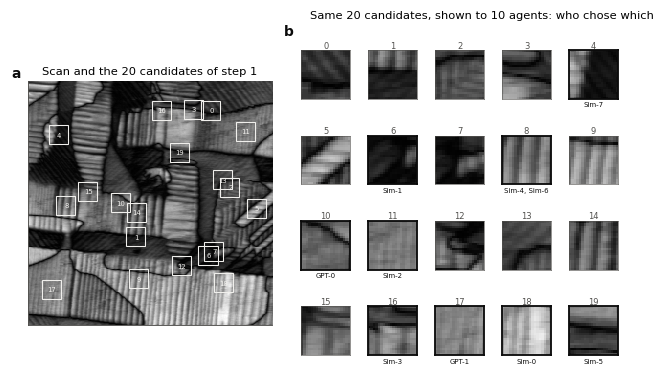

In [ ]:
fig = plots.fig_data(data, step=0, ref=L.index(CONTROLS[0] if CONTROLS else L[0]))
plots.save(fig, FIG_DIR, "fig1_data"); plt.show()

## 2. Representations
Every representation is computed for **every** crop of the scan (not only the candidates); that is what makes reward maps over the whole scan possible. Descriptor columns are standardised over all crops, so their weights can be compared.

In [ ]:
EMB = {name: cache(f"embedding_{name.replace(' ', '_')}", {"data": data, "rep": rep}, lambda rep=rep: rep.embed(data))
       for name, rep in REPRESENTATIONS.items()}
for name, E in EMB.items(): print(f"{name:20s} {E.shape}")
D = EMB[PRIMARY]
NAMES = list(REPRESENTATIONS[PRIMARY].feature_names)
GROUPS = REPRESENTATIONS[PRIMARY].groups if hasattr(REPRESENTATIONS[PRIMARY], "groups") else {"all": list(range(D.shape[1]))}
FAMILIES = list(GROUPS)
DESC.table() if PRIMARY == "descriptors" else pd.DataFrame({"feature": NAMES})

[cache] embedding_descriptors: computing ...
[cache] embedding_descriptors: done in 11s, saved embedding_descriptors_aa48111b617b.pkl
[cache] embedding_pixel_PCA: computing ...
[cache] embedding_pixel_PCA: done in 1s, saved embedding_pixel_PCA_d8b6de3658d9.pkl
[cache] embedding_structure_classes: computing ...
[cache] embedding_structure_classes: done in 0s, saved embedding_structure_classes_ad1d7357c54c.pkl
descriptors          (56169, 34)
pixel PCA            (56169, 20)
structure classes    (56169, 6)


,descriptor,family,meaning,source
0,mean,intensity,average brightness,built-in
1,median,intensity,median brightness,built-in
2,p05,intensity,5th percentile brightness,built-in
3,p95,intensity,95th percentile brightness,built-in
4,std,intensity,contrast (std of brightness),built-in
5,range,intensity,robust range p95-p05,built-in
6,skew,intensity,skewness of brightness,built-in
7,kurtosis,intensity,kurtosis of brightness,built-in
8,entropy,intensity,histogram entropy,built-in
9,two_level,intensity,Otsu separability: one bright + one dark level,built-in


## 3. Test 1 — does a rule exist that explains every pick?
A linear program searches all weightings *w* of the descriptors for the largest margin *t* such that, at every step, the picked patch scores at least *t* above each of the others (with ‖w‖₁ ≤ 1). *t* > 0 means a weighted sum reproduces **every** pick. We run it on the descriptors (linear rule) and on the descriptors plus their squares (quadratic rule). A **negative control** applies the quadratic test to random picks, which should never pass.

This is fitted and checked on the same decisions: it shows whether a rule *exists*, not whether it predicts new decisions (that is Test 2).

In [ ]:
Q = np.concatenate([D, D ** 2], 1)
rows = []
for a in ORDER:
    t = L.index(a); c, y = data.cand[t], data.choice[t]
    m1, w1 = max_margin(D[c], y)
    m2, _ = max_margin(Q[c], y)
    rows.append({"agent": a, "linear rule exact": m1 > 1e-6, "margin": round(m1, 4),
                 "picks reproduced by best-margin rule": int(((D[c] @ w1).argmax(1) == y).sum()),
                 "quadratic rule exact": m2 > 1e-6})
ident = pd.DataFrame(rows).set_index("agent")
rng = np.random.default_rng(0)
ref = data.cand[L.index(CONTROLS[-2] if len(CONTROLS) > 1 else L[0])]   # candidate sets of one control agent
neg = [max_margin(Q[ref], rng.integers(0, K, len(ref)))[0] > 1e-6 for _ in range(5)]
print(f"negative control: random picks separable in {sum(neg)} of {len(neg)} tries")
ident

negative control: random picks separable in 0 of 5 tries


,linear rule exact,margin,picks reproduced by best-margin rule,quadratic rule exact
agent,,,,
GPT-0,False,-0.0000,2,False
GPT-1,False,-0.0000,5,False
GPT-2,False,-0.0000,8,False
Sim-0,True,0.0531,100,True
Sim-1,True,0.0461,100,True
Sim-2,True,0.0419,100,True
Sim-3,False,-0.0000,4,False
Sim-4,True,0.0156,100,True
Sim-5,True,0.0534,100,True


saved ../figures/pipeline/fig2_identification.png


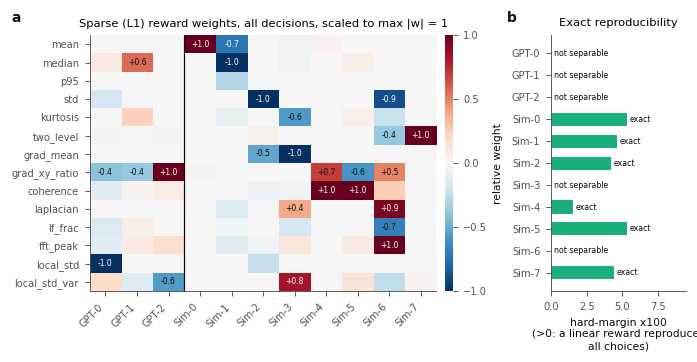

In [ ]:
# sparse rule weights on all decisions (L1 = 1.0), for the figure
W = np.array([ck.fit_linear(D[data.cand[L.index(a)]], data.choice[L.index(a)], l1=1.0) for a in ORDER])
fig = plots.fig_identification(W, ident["margin"].to_numpy(), NAMES, ORDER, split=len(TARGETS),
                               select_rows=[ORDER.index(a) for a in CONTROLS] or None)
plots.save(fig, FIG_DIR, "fig2_identification"); plt.show()

## 4. Test 2 — which method predicts picks it never saw?
For each agent the decisions are split into 5 groups; each method learns from 4 and predicts the 5th, rotating so every decision is predicted once, repeated with different splits. **The splits are identical for every method**, and all tuning happens inside the training decisions.

Scores per held-out decision: **top-1** (is the method's highest-scoring patch the one picked? chance = 1/K), and the **log-likelihood** of the actual pick, reported as **pseudo-R²** = 1 − LL / LL(random guessing): 0 = no better than guessing, 1 = every pick predicted with certainty. Intervals: 95% bootstrap over decisions.

In [ ]:
BENCH_SPEC = {"data": data, "methods": {m: (REPRESENTATIONS[r], model) for m, (r, model) in METHODS.items()}, "cv": CV}
cache.put("benchmark", BENCH_SPEC, pd.read_csv("../results/benchmark_per_decision.csv"))
bench = cache("benchmark", BENCH_SPEC,
              lambda: ck.cross_validate(data, METHODS, embeddings=EMB, folds=CV["folds"], repeats=CV["repeats"], seed=CV["seed"]))
summary = ck.summarise(bench, n_candidates=K); summary.attrs["n_candidates"] = K
print("held-out top-1 (chance = %.2f)" % (1 / K))
summary.pivot(index="trace", columns="method", values="top1").loc[ORDER, list(METHODS)].round(2)

[cache] benchmark: loaded benchmark_c4c2b451c293.pkl
held-out top-1 (chance = 0.05)


method,best single descriptor,"sparse linear, descriptors","dense linear, descriptors","GP, descriptors","dense linear, pixel PCA","GP, pixel PCA","dense linear, structure classes"
trace,,,,,,,
GPT-0,0.18,0.33,0.36,0.42,0.08,0.30,0.18
GPT-1,0.20,0.27,0.28,0.30,0.04,0.20,0.12
GPT-2,0.50,0.57,0.54,0.53,0.22,0.30,0.33
Sim-0,0.99,0.92,0.84,0.81,0.90,0.80,0.38
Sim-1,0.99,0.93,0.88,0.86,0.92,0.88,0.22
Sim-2,0.83,0.93,0.94,0.84,0.35,0.64,0.46
Sim-3,0.24,0.36,0.38,0.40,0.15,0.38,0.12
Sim-4,0.83,0.87,0.84,0.84,0.32,0.46,0.52
Sim-5,0.82,0.95,0.90,0.87,0.18,0.47,0.73


In [ ]:
print("held-out pseudo-R2")
summary.pivot(index="trace", columns="method", values="pseudo_r2").loc[ORDER, list(METHODS)].round(2)

held-out pseudo-R2


method,best single descriptor,"sparse linear, descriptors","dense linear, descriptors","GP, descriptors","dense linear, pixel PCA","GP, pixel PCA","dense linear, structure classes"
trace,,,,,,,
GPT-0,0.10,0.29,0.29,0.33,0.01,0.19,0.10
GPT-1,0.06,0.22,0.23,0.27,0.00,0.11,0.11
GPT-2,0.44,0.48,0.46,0.51,0.05,0.25,0.26
Sim-0,0.99,0.94,0.87,0.87,0.90,0.83,0.39
Sim-1,0.99,0.93,0.91,0.91,0.93,0.86,0.33
Sim-2,0.87,0.94,0.92,0.89,0.06,0.73,0.60
Sim-3,0.13,0.34,0.35,0.37,-0.00,0.33,0.06
Sim-4,0.85,0.90,0.86,0.85,0.21,0.50,0.62
Sim-5,0.80,0.95,0.93,0.90,0.02,0.46,0.72


saved ../figures/pipeline/fig3_benchmark.png


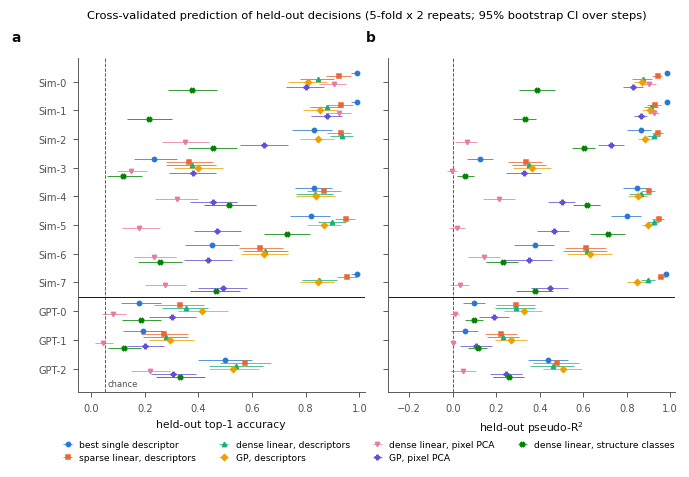

,method,top1
trace,,
GPT-0,"GP, descriptors",0.42
GPT-1,"GP, descriptors",0.30
GPT-2,"sparse linear, descriptors",0.57
Sim-0,best single descriptor,0.99
Sim-1,best single descriptor,0.99
Sim-2,"dense linear, descriptors",0.94
Sim-3,"GP, descriptors",0.40
Sim-4,"sparse linear, descriptors",0.87
Sim-5,"sparse linear, descriptors",0.95


In [ ]:
agents_fig = CONTROLS + TARGETS + [a for a in L if a not in TARGETS + CONTROLS]
fig = plots.fig_benchmark(summary, list(METHODS), agents_fig, split=len(CONTROLS),
                          title=f"Cross-validated prediction of held-out decisions ({CV['folds']}-fold x {CV['repeats']} repeats; 95% bootstrap CI over steps)")
plots.save(fig, FIG_DIR, "fig3_benchmark"); plt.show()
best = summary.loc[summary.groupby("trace")["top1"].idxmax(), ["trace", "method", "top1"]].set_index("trace").loc[ORDER]
best.round(2)

## 5. Ground truth — can we recover rules we wrote ourselves?
For GPT the true rule is unknown, so we test the methods on synthetic agents whose reward we wrote (section 0.4). They act on the same scan with random candidate sets, at several noise levels and numbers of decisions. Each method sees only the picks; we compare the recovered reward with the true one by rank correlation over crops (Spearman; 1 = same ranking of patches). This tells us which method to trust for which kind of rule, and how many decisions are needed.

In [ ]:
Dd = pd.DataFrame(D, columns=NAMES)
TRUE = {name: np.asarray(f(Dd, EMB), np.float64) for name, f in SYNTH_REWARDS.items()}
SYNTH_SPEC = {"data": data, "rewards": SYNTH_REWARDS, "true": TRUE, "grid": SYNTH_GRID,
              "models": {m: (REPRESENTATIONS[s[0]],) + tuple(s[1:]) for m, s in SYNTH_MODELS.items()}}
cache.put("synthetic", SYNTH_SPEC, pd.read_csv("../results/synth_results.csv"))
syn = cache("synthetic", SYNTH_SPEC,
            lambda: sy.recovery_grid(TRUE, SYNTH_MODELS, EMB, n_candidates=K, **SYNTH_GRID))
mid_tau = sorted(SYNTH_GRID["temperatures"])[len(SYNTH_GRID["temperatures"]) // 2]
n_ref = 100 if 100 in SYNTH_GRID["n_decisions"] else max(SYNTH_GRID["n_decisions"])
print(f"recovery (Spearman) with {n_ref} decisions, noise {mid_tau}")
syn[(syn.n == n_ref) & (syn.tau == mid_tau)].groupby(["reward", "model"])["rho"].mean().unstack()[list(SYNTH_MODELS)].round(2)

[cache] synthetic: loaded synthetic_c881368f1f7e.pkl
recovery (Spearman) with 100 decisions, noise 0.5


model,single,l1_desc,l2_desc,gp_desc,gp_pix
reward,,,,,
nonlinear (moderate contrast),0.34,0.61,0.61,0.81,0.54
outside library (texture match),0.43,0.72,0.73,0.73,0.82
single (brightness),0.88,0.96,0.95,0.95,0.96
sparse mix (3 features),0.37,0.97,0.96,0.95,0.48


saved ../figures/pipeline/fig4_synthetic.png


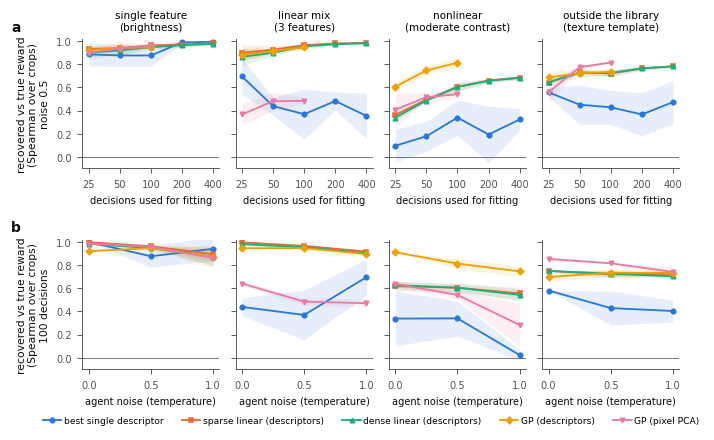

saved ../figures/pipeline/slide_recovery_chart.png


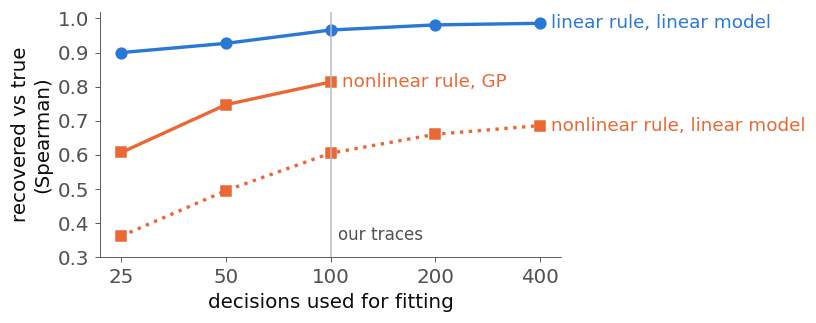

In [ ]:
fig = plots.fig_synthetic(syn, SYNTH_LABELS, SYNTH_TITLES, tau_for_n=mid_tau, n_for_tau=n_ref)
plots.save(fig, FIG_DIR, "fig4_synthetic"); plt.show()
fig = plots.fig_recovery_chart(syn, RECOVERY_CHART, tau=mid_tau, mark_n=n_ref)
plots.save(fig, FIG_DIR, "slide_recovery_chart", pdf=False); plt.show()

## 6. How do the target agents decide?
Five questions, each with a control.

1. **Content at all?** Held-out fit of the real picks vs `n_perm` copies in which every pick is replaced by a random candidate. *p* = (copies doing at least as well + 1) / (copies + 1).
2. **Which properties?** Refit with one descriptor family removed; the drop in held-out log-likelihood per decision is that family's importance. Stability selection: refit a sparse model on many random halves of the decisions and count how often each descriptor is kept, with the sign of its weight.
3. **Memory?** Add four history terms (position in the list, similarity to the last pick, distance on the scan to the last pick and to the nearest earlier pick) and measure the held-out gain. Control: the control agents have no memory, so their gains show the size of a spurious effect.
4. **Closest known strategy?** Fit a linear rule to each control agent; report where the target's picks rank under that rule (1 = always that rule's favourite, 0.5 = unrelated).
5. **Consistency.** For targets shown identical candidates: how often they picked the same patch, against the agreement each run's own fitted policy predicts if it were repeated.

In [ ]:
def target_diagnostics():
    out = {}
    rules = {s: ck.fit_linear(D[data.cand[L.index(s)]], data.choice[L.index(s)], l2=DIAG["rule_l2"]) for s in CONTROLS}
    for g in TARGETS:
        t = L.index(g); c, y = data.cand[t], data.choice[t]
        p = dg.permutation_test(D, c, y, n_perm=DIAG["n_perm"])
        fam = dg.family_importance(D, c, y, GROUPS)
        h = dg.history_test(data, t, D)
        out[g] = {"pseudo_r2": p["pseudo_r2"], "p": p["p"], "cv_ll": p["cv_ll"],
                  "null95_pseudo_r2": 1 - np.percentile(p["null"], 95) / CHANCE_LL,
                  "family_loss": {f: fam["all"] - fam["without_" + f] for f in GROUPS},
                  "history_gain": h["gain"], "history_weights": h["weights"],
                  "stability": dg.stability_selection(D, c, y, NAMES, l1=DIAG["stability_l1"], n_boot=DIAG["stability_n"]),
                  "similarity": {s: dg.strategy_similarity(D, c, y, w) for s, w in rules.items()}}
    out["_control_history"] = {s: dg.history_test(data, L.index(s), D)["gain"] for s in CONTROLS}
    out["_consistency"] = {}
    for i, a in enumerate(TARGETS):
        for b in TARGETS[i + 1:]:
            ta, tb = L.index(a), L.index(b)
            if np.array_equal(data.cand[ta], data.cand[tb]):
                out["_consistency"][f"{a} vs {b}"] = dg.consistency(D, data.cand[ta], data.choice[ta], data.choice[tb], lam=DIAG["consistency_l2"])
    return out

DIAG_SPEC = {"data": data, "rep": REPRESENTATIONS[PRIMARY], "targets": TARGETS, "controls": CONTROLS, "settings": DIAG}
diag = cache("diagnostics", DIAG_SPEC, target_diagnostics)

print("Q1-Q3")
pd.DataFrame({g: {"pseudo-R2": diag[g]["pseudo_r2"], "permutation p": diag[g]["p"],
                  **{f"loss without {f}": diag[g]["family_loss"][f] for f in FAMILIES},
                  "history gain (nats/decision)": diag[g]["history_gain"]} for g in TARGETS}).round(3)

[cache] diagnostics: loaded diagnostics_040c1c8f3eec.pkl
Q1-Q3


,GPT-0,GPT-1,GPT-2
pseudo-R2,0.269,0.247,0.483
permutation p,0.010,0.010,0.010
loss without intensity,0.092,0.319,-0.021
loss without edges,0.072,0.045,0.062
loss without texture,0.237,0.026,0.124
loss without layout,0.023,-0.014,-0.008
history gain (nats/decision),0.120,-0.002,0.003


In [ ]:
print("history gain of the memoryless controls:", {k: round(v, 3) for k, v in diag["_control_history"].items()})
for g in TARGETS:
    print(f"{g} most stable descriptors:", [(n, round(float(pr), 2), "+" if s > 0 else "-") for n, pr, s in diag[g]["stability"][:6]])
print("\nQ4: percentile of the targets' picks under each control agent's rule")
display(pd.DataFrame({g: diag[g]["similarity"] for g in TARGETS}).round(2))
print("Q5: consistency between targets shown identical candidates")
pd.DataFrame(diag["_consistency"]).round(3)

history gain of the memoryless controls: {'Sim-0': 0.015, 'Sim-1': -0.004, 'Sim-2': -0.0, 'Sim-3': 0.002, 'Sim-4': -0.014, 'Sim-5': -0.029, 'Sim-6': -0.027, 'Sim-7': -0.014}
GPT-0 most stable descriptors: [('acorr_x6', 1.0, '-'), ('acorr_y6', 1.0, '-'), ('local_std_var', 0.99, '+'), ('coherence', 0.98, '-'), ('centre_border', 0.97, '-'), ('bimodality', 0.96, '-')]
GPT-1 most stable descriptors: [('skew', 1.0, '-'), ('acorr_y6', 0.93, '+'), ('kurtosis', 0.92, '+'), ('orient_sin', 0.92, '+'), ('entropy', 0.91, '-'), ('grad_y', 0.89, '-')]
GPT-2 most stable descriptors: [('acorr_x1', 1.0, '-'), ('acorr_y1', 0.96, '-'), ('grad_xy_ratio', 0.89, '+'), ('coherence', 0.88, '+'), ('p05', 0.7, '+'), ('orient_sin', 0.68, '-')]

Q4: percentile of the targets' picks under each control agent's rule


,GPT-0,GPT-1,GPT-2
Sim-0,0.52,0.62,0.66
Sim-1,0.44,0.47,0.35
Sim-2,0.34,0.69,0.65
Sim-3,0.68,0.36,0.21
Sim-4,0.44,0.61,0.82
Sim-5,0.40,0.52,0.45
Sim-6,0.38,0.43,0.88
Sim-7,0.43,0.41,0.44


Q5: consistency between targets shown identical candidates


,GPT-0 vs GPT-1
observed,0.010
expected_self_a,0.156
expected_self_b,0.193
expected_cross,0.029
chance,0.050


saved ../figures/pipeline/fig6_targets.png


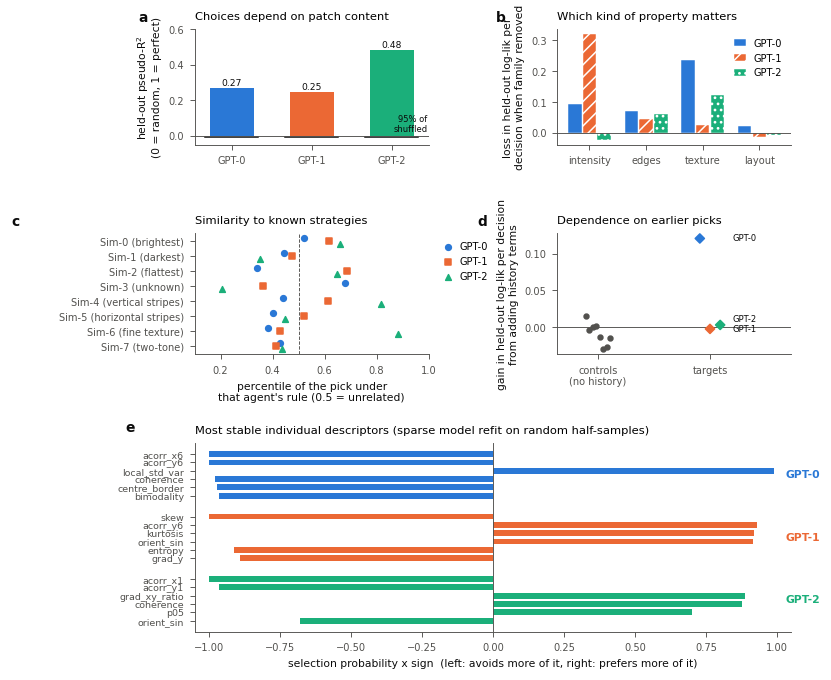

In [ ]:
fig = plots.fig_targets(diag, TARGETS, CONTROLS, FAMILIES, AGENT_NOTES)
plots.save(fig, FIG_DIR, "fig6_targets"); plt.show()

## 7. Reward maps and structure preferences
Each agent's chosen model (`MAP_MODEL`) is refitted on all its decisions and applied to **every** crop of the scan, giving a map of where its learned rule points. Maps are standardised; their uncertainty is the standard deviation over `MAP_BOOTSTRAPS` refits on resampled decisions.

Separately, every pixel is labelled with a generic structure class (flat, vertical / horizontal / diagonal stripes, boundary, irregular) from the local structure tensor and edge strength. A softmax model whose only inputs are the class fractions of each patch then reads as "prefers patches with more of class X"; its held-out pseudo-R² says how much of the behaviour these six numbers explain.

In [ ]:
def map_model(a):
    return ck.GPPreference() if MAP_MODEL.get(a, "sparse linear") == "GP" else ck.LinearLogit("l1", grid=[1.0])

def reward_maps():
    rng = np.random.default_rng(0)
    z = lambda f: (f - f.mean()) / f.std()
    maps, sds = {}, {}
    allc = np.arange(len(D)); S = data.cand.shape[1]
    for t, a in enumerate(L):
        fit = lambda steps: map_model(a).fit(D, data.cand[t][steps], data.choice[t][steps]).reward(D, allc)
        base = fit(np.arange(S))
        boots = [fit(rng.integers(0, S, S)) for _ in range(MAP_BOOTSTRAPS)]
        maps[a] = z(base).reshape(data.grid)
        sds[a] = np.std([z(b) for b in boots], 0).reshape(data.grid)
    return maps, sds

MAP_SPEC = {"data": data, "rep": REPRESENTATIONS[PRIMARY], "models": {a: repr(map_model(a)) for a in L}, "boot": MAP_BOOTSTRAPS}
maps, sds = cache("reward_maps", MAP_SPEC, reward_maps)
print("mean bootstrap s.d. of the standardised map:", {a: round(float(sds[a].mean()), 2) for a in ORDER})
corr = pd.DataFrame([[spearmanr(maps[a].ravel(), maps[b].ravel()).statistic for b in ORDER] for a in ORDER], index=ORDER, columns=ORDER)
print("Spearman correlation between reward maps")
corr.round(2)

[cache] reward_maps: loaded reward_maps_9d2feb4e77df.pkl
mean bootstrap s.d. of the standardised map: {'GPT-0': 0.38, 'GPT-1': 0.38, 'GPT-2': 0.3, 'Sim-0': 0.08, 'Sim-1': 0.1, 'Sim-2': 0.06, 'Sim-3': 0.39, 'Sim-4': 0.11, 'Sim-5': 0.1, 'Sim-6': 0.29, 'Sim-7': 0.04}
Spearman correlation between reward maps


,GPT-0,GPT-1,GPT-2,Sim-0,Sim-1,Sim-2,Sim-3,Sim-4,Sim-5,Sim-6,Sim-7
GPT-0,1.00,-0.31,-0.44,-0.23,0.16,-0.30,0.41,-0.38,-0.18,-0.26,-0.10
GPT-1,-0.31,1.00,0.13,0.23,-0.13,0.44,-0.19,0.20,-0.11,-0.25,-0.12
GPT-2,-0.44,0.13,1.00,0.37,-0.32,0.28,-0.57,0.43,-0.11,0.60,-0.38
Sim-0,-0.23,0.23,0.37,1.00,-0.98,-0.28,-0.05,0.29,-0.07,0.30,-0.11
Sim-1,0.16,-0.13,-0.32,-0.98,1.00,0.42,-0.01,-0.27,0.03,-0.32,0.06
Sim-2,-0.30,0.44,0.28,-0.28,0.42,1.00,-0.42,0.10,-0.12,-0.08,-0.38
Sim-3,0.41,-0.19,-0.57,-0.05,-0.01,-0.42,1.00,-0.28,-0.07,-0.30,0.35
Sim-4,-0.38,0.20,0.43,0.29,-0.27,0.10,-0.28,1.00,0.44,0.31,-0.01
Sim-5,-0.18,-0.11,-0.11,-0.07,0.03,-0.12,-0.07,0.44,1.00,0.11,0.14
Sim-6,-0.26,-0.25,0.60,0.30,-0.32,-0.08,-0.30,0.31,0.11,1.00,-0.32


,GPT-0,GPT-1,GPT-2,Sim-0,Sim-1,Sim-2,Sim-3,Sim-4,Sim-5,Sim-6,Sim-7
flat,-0.14,0.49,0.44,-0.00,1.42,1.91,-0.01,0.35,0.05,0.20,0.44
stripes |,-0.01,0.00,0.68,1.01,-1.30,-0.90,-0.30,1.65,-0.84,0.68,-0.40
stripes -,-0.17,-0.36,-0.22,-0.74,-0.75,-0.92,0.06,-1.19,1.90,0.28,-0.40
stripes /,0.46,-0.37,-1.23,-0.78,-0.01,-0.20,0.03,-1.81,-0.64,-1.43,-0.70
boundary,0.12,0.32,-0.92,0.31,0.37,-0.64,0.50,-0.42,0.53,-0.97,1.54
irregular,0.19,-0.69,-0.38,-0.79,0.73,-0.24,0.17,-0.69,-1.86,-0.45,-0.24
held-out pseudo-R2,0.08,0.12,0.27,0.39,0.33,0.60,0.06,0.62,0.72,0.24,0.38


saved ../figures/pipeline/fig5_maps_structure.png


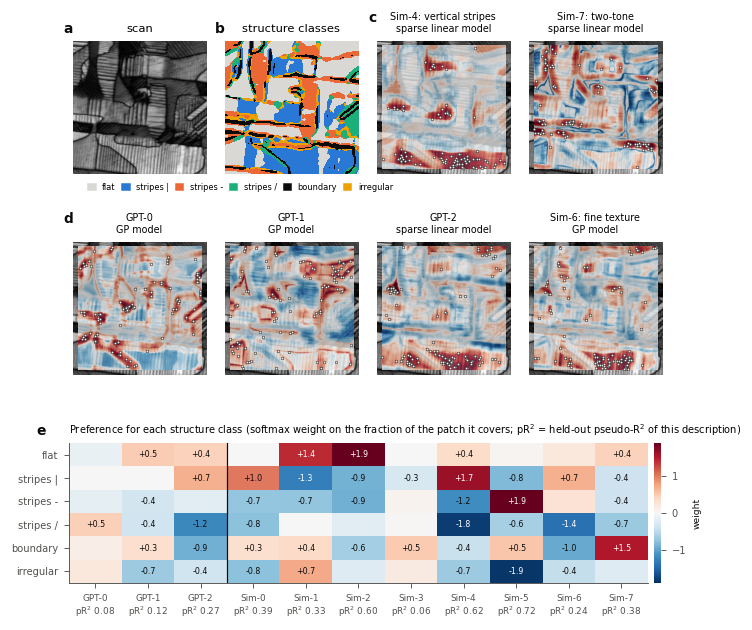

In [ ]:
SC = REPRESENTATIONS.get("structure classes", ck.StructureClasses())
S_emb = EMB.get("structure classes", SC.embed(data)) if "structure classes" in EMB else SC.embed(data)
struct_lab = SC.labels(data)
struct_w = {a: ck.fit_linear(S_emb[data.cand[L.index(a)]], data.choice[L.index(a)], l2=1.0) for a in ORDER}
struct_pr2 = {a: 1 + dg.cv_loglik(S_emb[data.cand[L.index(a)]], data.choice[L.index(a)], lam=1.0) / np.log(K) for a in ORDER}
tab = pd.DataFrame(struct_w, index=SC.feature_names); tab.loc["held-out pseudo-R2"] = pd.Series(struct_pr2)
display(tab.round(2))
fig = plots.fig_maps(data, maps, [p for p in MAP_PANELS if p[0] in L], struct_lab, SC.feature_names, struct_w, struct_pr2,
                     ORDER, split=len(TARGETS), model_names={a: MAP_MODEL.get(a, "sparse linear") for a in L})
plots.save(fig, FIG_DIR, "fig5_maps_structure"); plt.show()

## 8. Key numbers
A summary generated from the results above (these are the numbers quoted on the slides), and a copy of the main results in `results/pipeline/`.

In [ ]:
from decimal import Decimal, ROUND_HALF_UP
r2 = lambda x, n=2: str(Decimal(repr(float(x))).quantize(Decimal(1).scaleb(-n), ROUND_HALF_UP))   # round half up
lines = []
exact = [a for a in ORDER if ident.loc[a, "linear rule exact"]]
quad = [a for a in ORDER if ident.loc[a, "quadratic rule exact"] and not ident.loc[a, "linear rule exact"]]
lines.append(f"Test 1: exact linear rule for {', '.join(exact) or 'no agent'}; quadratic only: {', '.join(quad) or 'none'}; "
             f"random picks separable in {sum(neg)}/{len(neg)} tries.")
lines.append("Test 2 (best held-out top-1, chance %.2f): " % (1 / K) + "; ".join(f"{a} {r2(best.loc[a, 'top1'])} ({best.loc[a, 'method']})" for a in ORDER))
rec = syn[(syn.n == n_ref) & (syn.tau == mid_tau)].groupby(["reward", "model"])["rho"].mean()
lines.append(f"Ground truth ({n_ref} decisions, noise {mid_tau}): " + "; ".join(f"{r}: best {SYNTH_LABELS.get(rec[r].idxmax(), rec[r].idxmax())} {r2(rec[r].max())}" for r in SYNTH_REWARDS))
for g in TARGETS:
    d = diag[g]; top1 = best.loc[g, "top1"]
    fam = max(d["family_loss"], key=d["family_loss"].get)
    sim = max(d["similarity"], key=d["similarity"].get) if d["similarity"] else None
    lines.append(f"{g}: pseudo-R2 {r2(d['pseudo_r2'])} (p = {r2(d['p'])}); top-1 {r2(top1)} = {r2(top1 * K, 1)}x chance; "
                 f"most important family {fam} ({r2(d['family_loss'][fam])}); history gain {d['history_gain']:+.3f}"
                 + (f"; closest control {sim} (percentile {r2(d['similarity'][sim])}, map correlation {r2(corr.loc[g, sim])})" if sim else ""))
if diag["_control_history"]:
    lines.append(f"Largest history gain among memoryless controls: {max(diag['_control_history'].values()):.3f}")
for k, v in diag["_consistency"].items():
    a, b = k.split(" vs ")
    lines.append(f"{k}: same pick {v['observed']:.2f}; expected self-agreement {v['expected_self_a']:.2f} / {v['expected_self_b']:.2f}; "
                 f"map correlation {corr.loc[a, b]:.2f}")
print("\n".join(lines))

out = os.path.join(RESULTS_DIR, "pipeline"); os.makedirs(out, exist_ok=True)
ident.to_csv(os.path.join(out, "exact_reproducibility.csv"))
summary.to_csv(os.path.join(out, "benchmark_summary.csv"), index=False)
syn.to_csv(os.path.join(out, "synthetic_recovery.csv"), index=False)
json.dump({g: {k: v for k, v in diag[g].items()} for g in TARGETS} | {k: diag[k] for k in ("_control_history", "_consistency")},
          open(os.path.join(out, "target_diagnostics.json"), "w"), indent=1, default=float)
open(os.path.join(out, "key_numbers.txt"), "w").write("\n".join(lines))
print("\nsaved to", out)

Test 1: exact linear rule for Sim-0, Sim-1, Sim-2, Sim-4, Sim-5, Sim-7; quadratic only: Sim-6; random picks separable in 0/5 tries.
Test 2 (best held-out top-1, chance 0.05): GPT-0 0.42 (GP, descriptors); GPT-1 0.30 (GP, descriptors); GPT-2 0.58 (sparse linear, descriptors); Sim-0 0.99 (best single descriptor); Sim-1 0.99 (best single descriptor); Sim-2 0.94 (dense linear, descriptors); Sim-3 0.40 (GP, descriptors); Sim-4 0.87 (sparse linear, descriptors); Sim-5 0.95 (sparse linear, descriptors); Sim-6 0.65 (dense linear, descriptors); Sim-7 0.99 (best single descriptor)
Ground truth (100 decisions, noise 0.5): single (brightness): best sparse linear (descriptors) 0.96; sparse mix (3 features): best sparse linear (descriptors) 0.97; nonlinear (moderate contrast): best GP (descriptors) 0.81; outside library (texture match): best GP (pixel PCA) 0.82
GPT-0: pseudo-R2 0.27 (p = 0.01); top-1 0.42 = 8.3x chance; most important family texture (0.24); history gain +0.120; closest control Sim-3

## Appendix — adapting the pipeline: a worked example
A quick, self-contained demonstration of the two most common changes, without touching the study configuration above.

1. **A new descriptor.** We add `dark_fraction` (share of pixels below 0.3) to the descriptor set.
2. **A new synthetic agent** whose true rule uses it: it prefers patches with more dark area and less contrast.

We then check that Test 1 finds an exact rule for a noiseless version of this agent, and that the sparse model recovers the rule from 100 noisy decisions and names `dark_fraction` as its largest weight. In the real workflow you would make the same changes in section 0 and rerun everything.

In [ ]:
DESC2 = DESC.add("dark_fraction", "intensity", "fraction of pixels below 0.3", lambda P: (P < 0.3).mean((1, 2)))
D2 = DESC2.embed(data)
names2 = DESC2.feature_names
true2 = 0.8 * D2[:, names2.index("dark_fraction")] - 0.4 * D2[:, names2.index("std")]

# Test 1 on a noiseless version: an exact rule should exist
agent0 = sy.SyntheticAgent(true2, temperature=0.0, n_candidates=K)
c0, y0 = agent0.simulate(100, np.random.default_rng(1))
print("noiseless agent, exact linear rule exists:", max_margin(D2[c0], y0)[0] > 1e-6)

# recovery from 100 noisy decisions
agent = sy.SyntheticAgent(true2, temperature=0.5, n_candidates=K)
res = {m: sy.recovery(agent, D2, model, 100, np.random.default_rng(2))
       for m, model in {"sparse linear": ck.LinearLogit("l1", grid=[1.0]), "GP": ck.GPPreference()}.items()}
print(pd.DataFrame(res).T.round(2))
c, y = agent.simulate(100, np.random.default_rng(3))
w = ck.LinearLogit("l1", grid=[1.0]).fit(D2, c, y).w
print("largest sparse weights:", [(names2[j], round(float(w[j]), 2)) for j in np.argsort(-np.abs(w))[:4]])

noiseless agent, exact linear rule exists: True
                acc  oracle   rho
sparse linear  0.39    0.41  0.97
GP             0.40    0.41  0.95
largest sparse weights: [('dark_fraction', 1.83), ('lf_frac', -0.49), ('lr_step', -0.47), ('coarse_std', 0.43)]
